In [20]:
import os
import pandas as pd 
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

path=r'C:\Users\92san\Downloads\archive'
print("Files in folder:",os.listdir(path))
churn_data=pd.read_excel(r'C:\Users\92san\Downloads\archive\Telco_customer_churn.xlsx')
churn_data.head()
churn_data.info()

print("All column names:")
print(churn_data.columns.tolist())
if 'Churn Value' in churn_data.columns:
    print("\nDistribution of Churn Value:")
    print(churn_data.value_counts('Churn Value'))
elif 'Churn Label' in churn_data.columns:
    print("\nDistribution of Churn Label:")
    print(churn_data.value_counts('Churn Label'))
print("---Dataframe Info---")
churn_data.info()
print("\n---Missing Values Per Column---")
print(churn_data.isnull().sum())


file_path = r'C:\Users\92san\Downloads\archive\Telco_customer_churn.xlsx'
churn_data = pd.read_excel(file_path)
class TelcoDataCleaner(BaseEstimator, TransformerMixin):
    """
    A production-grade custom transformer to clean Telco Churn Data.
    """
    def __init__ (self, drop_columns=None):
       self.drop_columns= drop_columns if drop_columns else ['CustomerID', 'Count', 'Country', 'State', 'City', 'Lat Long']
       self.median_total_charges= None
    def fit(self, X, y=None):
        if 'Total Charges' in X.columns:
            coerced_charges= pd.to_numeric(X['Total Charges'],errors='coerce')
            self.median_total_charges= coerced_charges.median()
        return self
    def transform(self, X):
        X_clean= X.copy()
        if 'Total Charges' in X_clean.columns:
            X_clean['Total Charges']= pd.to_numeric(X_clean['Total Charges'], errors='coerce')
            X_clean['Total Charges']= X_clean['Total Charges'].fillna(self.median_total_charges)
        if 'Tenure Months' in X_clean.columns and 'Monthly Charges' in X_clean.columns:
            expected_total= X_clean['Tenure Months']* X_clean['Monthly Charges']
            X_clean['Billing_Discrepancy_Ratio'] = (X_clean['Total Charges']-expected_total)/ (X_clean['Monthly Charges']+1e-5)
        existing_drops = [col for col in self.drop_columns if col in X_clean.columns]
        X_clean= X_clean.drop(columns=existing_drops)
        return X_clean
cleaner = TelcoDataCleaner()
churn_clean = cleaner.fit_transform(churn_data)
print(f" pipeline executed succesfully. Cleaned Data Shape: {churn_clean.shape}")
print("\nNew engineered features added:")
print(churn_clean[['Total Charges', 'Billing_Discrepancy_Ratio']].head(3))

class TelcoCategoricalEncoder(BaseEstimator, TransformerMixin):
     def __init__(self):
        self.encoder_columns = []
        
     def  fit(self, X, y=None):
        self.encoder_columns = [col for col in X.columns if X[col].dtype=='object' and col !='Churn Value']
        return self
        
     def transform(self, X):
        X_encoded = X.copy()
        X_encoded = pd.get_dummies(X_encoded, columns=self.encoder_columns, drop_first=True)
        
        for col in X_encoded.columns:
            if X_encoded[col].dtype =='bool':
                X_encoded[col] = X_encoded[col].astype(int)
        return X_encoded
        
cleaner = TelcoDataCleaner()
churn_clean = cleaner.fit_transform(churn_data)

encoder = TelcoCategoricalEncoder()
churn_final = encoder.fit_transform(churn_clean)

print(f" pipeline complete. Final Cleaned & Encoded Shape: {churn_final.shape}")
print("\nFirst 3 rows of the final processed dataset (showing first 5 columns):")
print(churn_final.iloc[:, :5].head(3))

X = churn_final.select_dtypes(include=[np.number]).drop(columns=['Churn Value'], errors='ignore')
y = churn_final['Churn Value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train-Test Split completed succesfully!")
print(f"Total Features count: {X.shape[1]}")
print(f"X_train shape (Training Data): {X_train.shape}")
print(f"X_test shape (Testing Data): {X_test.shape}")
print(f"y_train Churn distribution:\n{y_train.value_counts(normalize=True)}")

model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Entire Pipeline and Model Training completed succesfully!")
print(f"Test Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred)) 


    

Files in folder: ['Telco_customer_churn.xlsx']
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   s

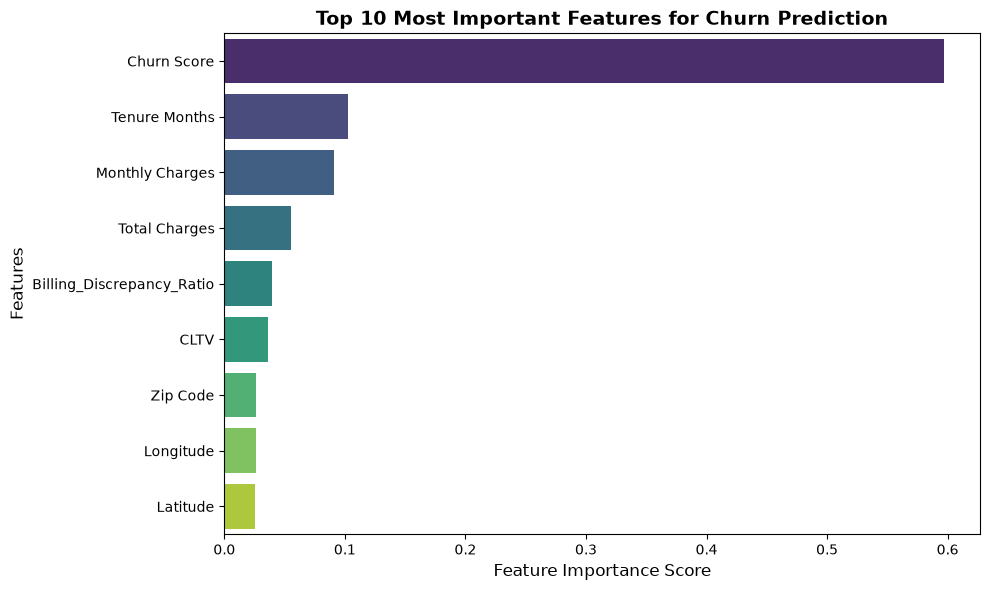

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
importances = model.feature_importances_
feature_names = X.columns
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
top_features = feature_imp_df.sort_values(by='Importance', ascending=False).head(10)
plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=top_features, palette='viridis', hue='Feature', legend=False)
plt.title('Top 10 Most Important Features for Churn Prediction', fontsize=14, fontweight='bold')
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

In [24]:
import joblib
project_artifacts = {
    'cleaner': cleaner,
    'encoder': encoder,
    'model': model,
    'features': X.columns.tolist()
}
joblib.dump(project_artifacts, 'telco_churn_pipeline.joblib')
print("Model and Preprocessing pipelines saved succesfully as 'telco_churn_pipeline.joblib'!")

Model and Preprocessing pipelines saved succesfully as 'telco_churn_pipeline.joblib'!
